# Importation, statistiques descriptives et graphiques


(29, 9)
         calories      sodium     calcium    lipides     retinol    folates  \
count   29.000000   29.000000   29.000000  29.000000   29.000000  29.000000   
mean   300.034483  210.086207  185.734483  24.158621   67.562069  13.010345   
std     91.914356  108.678923   72.528882   8.129642   24.163098  11.723339   
min     70.000000   22.000000   72.600000   3.400000   37.100000   1.200000   
25%    292.000000  140.000000  132.900000  23.400000   51.600000   4.900000   
50%    321.000000  223.000000  202.300000  26.300000   62.300000   6.400000   
75%    355.000000  276.000000  220.500000  29.100000   76.400000  21.100000   
max    406.000000  432.000000  334.600000  33.300000  150.500000  36.400000   

       proteines  cholesterol  magnesium  
count  29.000000    29.000000  29.000000  
mean   20.168966    74.586207  26.965517  
std     6.959788    28.245755  11.318388  
min     4.100000    10.000000  10.000000  
25%    17.800000    70.000000  20.000000  
50%    21.000000    80

array([[<Axes: xlabel='calories', ylabel='calories'>,
        <Axes: xlabel='sodium', ylabel='calories'>,
        <Axes: xlabel='calcium', ylabel='calories'>,
        <Axes: xlabel='lipides', ylabel='calories'>,
        <Axes: xlabel='retinol', ylabel='calories'>,
        <Axes: xlabel='folates', ylabel='calories'>,
        <Axes: xlabel='proteines', ylabel='calories'>,
        <Axes: xlabel='cholesterol', ylabel='calories'>,
        <Axes: xlabel='magnesium', ylabel='calories'>],
       [<Axes: xlabel='calories', ylabel='sodium'>,
        <Axes: xlabel='sodium', ylabel='sodium'>,
        <Axes: xlabel='calcium', ylabel='sodium'>,
        <Axes: xlabel='lipides', ylabel='sodium'>,
        <Axes: xlabel='retinol', ylabel='sodium'>,
        <Axes: xlabel='folates', ylabel='sodium'>,
        <Axes: xlabel='proteines', ylabel='sodium'>,
        <Axes: xlabel='cholesterol', ylabel='sodium'>,
        <Axes: xlabel='magnesium', ylabel='sodium'>],
       [<Axes: xlabel='calories', ylabel='calc

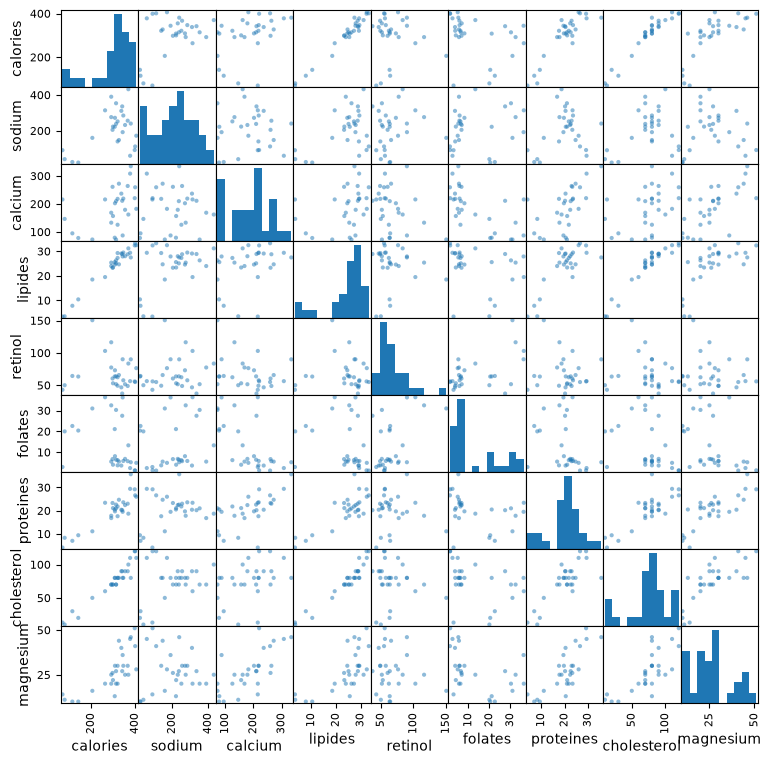

In [8]:
#modification du dossier par défaut
import os
#importation des données
import pandas
fromage = pandas.read_table("fromage.txt",sep="\t",header=0,index_col=0)
#dimension des données
print(fromage.shape)
#statistiques descriptives
print(fromage.describe())
#graphique - croisement deux à deux des variables
from pandas.plotting import scatter_matrix
scatter_matrix(fromage,figsize=(9,9))

# Classification ascendante hiérarchique
Utilisation du package « scipy »

In [9]:
from sklearn import preprocessing
fromage_cr = preprocessing.scale(fromage)

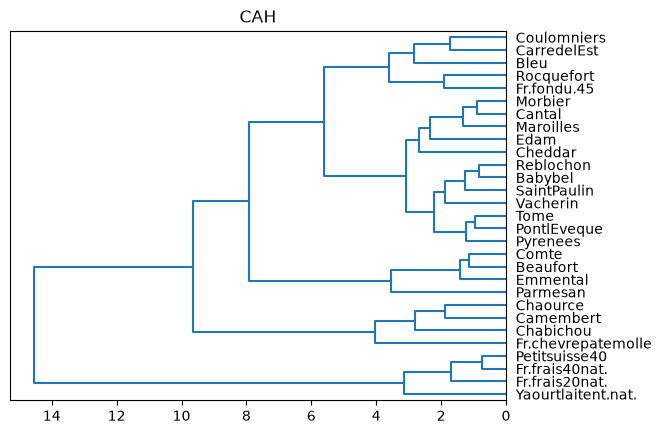

In [10]:
#librairies pour la CAH
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
#générer la matrice des liens
Z = linkage(fromage_cr,method='ward',metric='euclidean')
#affichage du dendrogramme
plt.title("CAH")
dendrogram(Z,labels=fromage.index,orientation='left',color_threshold=0)
plt.show()

# Découpage en classes – Matérialisation des groupes

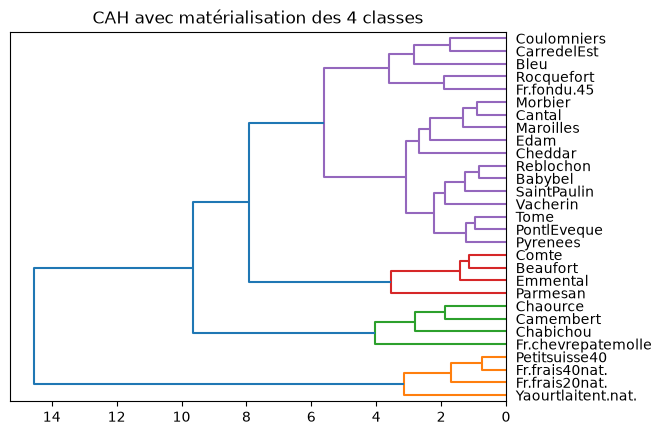

groupes_cah: [4 4 3 4 2 4 2 2 4 3 4 4 3 2 4 1 1 4 4 3 1 4 4 4 4 4 4 4 1]


,Fromages
1,Fr.frais20nat.
1,Yaourtlaitent.nat.
1,Petitsuisse40
1,Fr.frais40nat.
2,Fr.chevrepatemolle
2,Chabichou
2,Camembert
2,Chaource
3,Parmesan
3,Comte


In [11]:
from scipy.cluster.hierarchy import fcluster
#matérialisation des 4 classes (hauteur t = 7)
plt.title('CAH avec matérialisation des 4 classes')
dendrogram(Z,labels=fromage.index,orientation='left',color_threshold=7)
plt.show()
#découpage à la hauteur t = 7 ==> identifiants de 4 groupes obtenus
groupes_cah = fcluster(Z,t=7,criterion='distance')
print("groupes_cah:", groupes_cah)
#index triés des groupes
import numpy as np
idg = np.argsort(groupes_cah)
#affichage des observations et leurs groupes
display(pandas.DataFrame(fromage.index[idg],groupes_cah[idg]))

In [12]:
print(Z[:, 2])

[ 0.7356902   0.82483528  0.89672969  0.95935419  1.14064288  1.24708148
  1.24972145  1.32826122  1.42130185  1.70034202  1.72093864  1.86859757
  1.88685685  1.92182722  2.20413434  2.35092294  2.69019816  2.8108311
  2.83244751  3.09641867  3.14971979  3.55080524  3.5931852   4.0451875
  5.61774478  7.92082284  9.64780285 14.55808188]


# Méthode des centres mobiles
Utilisation du package « scikit-learn »

In [13]:
#k-means sur les données centrées et réduites
from sklearn import cluster
kmeans = cluster.KMeans(n_clusters=4)
kmeans.fit(fromage_cr)
#index triés des groupes
idk = np.argsort(kmeans.labels_)
#affichage des observations et leurs groupes
print(pandas.DataFrame(fromage.index[idk],kmeans.labels_[idk]))
#distances aux centres de classes des observations
print(kmeans.transform(fromage_cr))
#correspondance avec les groupes de la CAH
pandas.crosstab(groupes_cah,kmeans.labels_)

             Fromages
0         CarredelEst
0            Chaource
0           Chabichou
0           Camembert
0  Fr.chevrepatemolle
0         Coulomniers
1            Beaufort
1               Comte
1                Edam
1            Emmental
1             Cheddar
1            Parmesan
2  Yaourtlaitent.nat.
2       Petitsuisse40
2      Fr.frais40nat.
2      Fr.frais20nat.
3         Fr.fondu.45
3             Babybel
3                Bleu
3              Cantal
3             Morbier
3         PontlEveque
3            Pyrenees
3           Maroilles
3           Reblochon
3          Rocquefort
3                Tome
3         SaintPaulin
3            Vacherin
[[2.22366092 4.96135531 5.52563871 2.8747584 ]
 [3.0178739  2.57234902 5.19015189 0.72270816]
 [5.16141204 1.00918163 7.50534896 2.96554549]
 [3.23696124 3.71377754 6.12458901 2.05877139]
 [1.93343014 4.92555984 5.40377152 3.50921027]
 [4.02486207 2.01139577 6.29601131 1.22881552]
 [1.77869718 4.30518991 5.92595629 3.41671778]
 [1.0323722

col_0,0,1,2,3
row_0,,,,
1,0,0,4,0
2,4,0,0,0
3,0,4,0,0
4,2,2,0,13


## Aide à la détection du nombre adéquat de groupes


[0.48626255 0.38724166 0.35841693 0.31838275 0.20947404 0.31240591
 0.20080486 0.18321917 0.21704162]


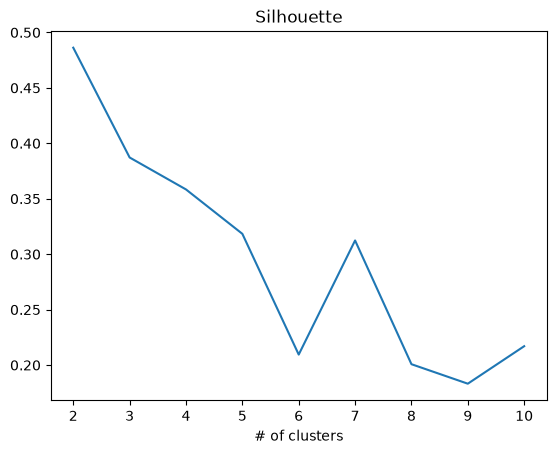

In [14]:
#librairie pour évaluation des partitions
from sklearn import metrics
#utilisation de la métrique "silhouette"
#faire varier le nombre de clusters de 2 à 10
res = np.arange(9,dtype="double")
for k in np.arange(9):
  km = cluster.KMeans(n_clusters=k+2)
  km.fit(fromage_cr)
  res[k] = metrics.silhouette_score(fromage_cr,km.labels_)
print(res)
#graphique
import matplotlib.pyplot as plt
plt.title("Silhouette")
plt.xlabel("# of clusters")
plt.plot(np.arange(2,11,1),res)
plt.show()

# INTERPRÉTATION DES CLASSES

In [16]:
#moyenne par variable
m = fromage_cr.mean()
#TSS
TSS = fromage_cr.shape[0]*fromage_cr.var(ddof=0)
print(TSS)
#data.frame conditionnellement aux groupes
gb = fromage.groupby(kmeans.labels_)
#effectifs conditionnels
nk = gb.size()
print(nk)
#moyennes conditionnelles
mk = gb.mean()
print(mk)
#pour chaque groupe écart à la moyenne par variable
EMk = (mk-m)**2
#pondéré par les effectifs du groupe
EM = EMk.multiply(nk,axis=0)
#somme des valeurs => BSS
BSS = np.sum(EM,axis=0)
print(BSS)
#carré du rapport de corrélation
#variance expliquée par l'appartenance aux groupes
#pour chaque variable
R2 = BSS/TSS
print(R2)

29.0
0     6
1     6
2     4
3    13
dtype: int64
     calories      sodium     calcium    lipides    retinol    folates  \
0  288.000000  252.916667  110.100000  23.866667  95.866667  31.266667   
1  382.000000  137.333333  262.866667  29.966667  66.533333   3.416667   
2  101.750000   44.750000  133.750000   6.275000  55.150000  16.475000   
3  328.769231  274.769231  201.038462  27.115385  58.792308   7.946154   

   proteines  cholesterol  magnesium  
0  18.883333    68.333333  21.666667  
1  28.600000   103.333333  42.500000  
2   7.200000    18.250000  11.250000  
3  20.861538    81.538462  27.076923  
calories       2.819780e+06
sodium         1.486450e+06
calcium        1.084296e+06
lipides        1.852139e+04
retinol        1.388037e+05
folates        7.842209e+03
proteines      1.291225e+04
cholesterol    1.798464e+05
magnesium      2.369149e+04
dtype: float64
calories       97233.791114
sodium         51256.884505
calcium        37389.504686
lipides          638.668583
retin

## Analyse en composantes principales (ACP)


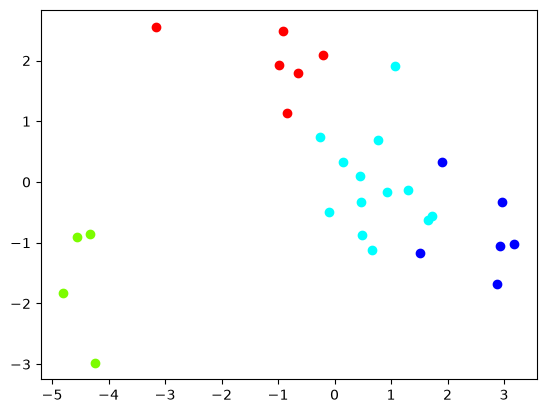

In [17]:
# ACP
from sklearn.decomposition import PCA
acp = PCA(n_components=2).fit_transform(fromage_cr)
#projeter dans le plan factoriel
#avec un code couleur différent selon le groupe
#remarquer le rôle de zip() dans la boucle
for couleur,k in zip(['red','blue','lawngreen','aqua'],[0,1,2,3]):
  plt.scatter(acp[kmeans.labels_==k,0],acp[kmeans.labels_==k,1],c=couleur)
plt.show()

# Approfondir l’analyse
Retirer les fromage_crs frais du jeu de données


(23, 9)


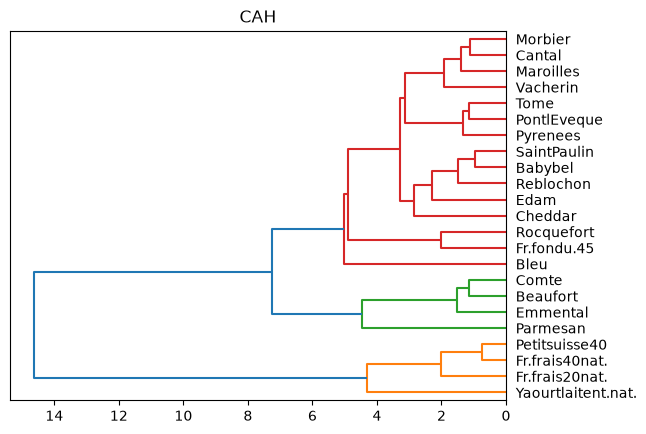

[3 2 3 3 3 2 3 2 3 1 1 3 3 2 1 3 3 3 3 3 3 3 1]


In [19]:
from sklearn import preprocessing
#retirer des observations le groupe n°0 du k-means précédent
fromage_cr_subset = fromage.iloc[kmeans.labels_!=0,:]
print(fromage_cr_subset.shape)
#centrer et réduire
fromage_cr_subset_cr = preprocessing.scale(fromage_cr_subset)
#générer la matrice des liens
Z_subset = linkage(fromage_cr_subset_cr,method='ward',metric='euclidean')
#cah et affichage du dendrogramme
plt.title("CAH")
dendrogram(Z_subset,labels=fromage_cr_subset.index,orientation='left',color_threshold=7)
plt.show()
#groupes
groupes_subset_cah = fcluster(Z_subset,t=7,criterion='distance')
print(groupes_subset_cah)

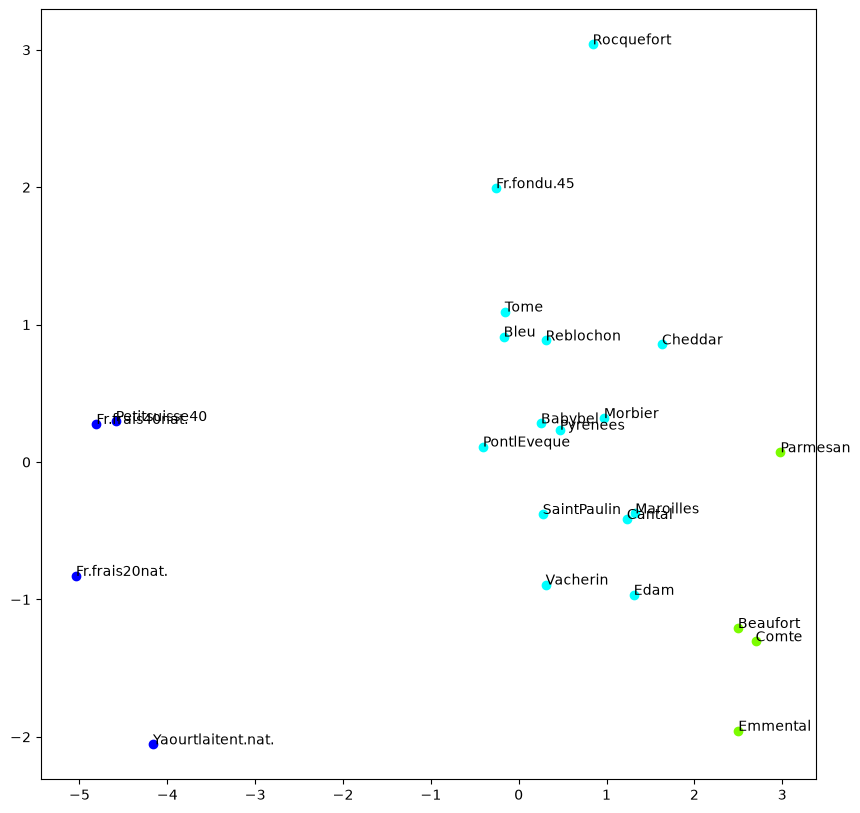

In [20]:
#ACP
acp_subset = PCA(n_components=2).fit_transform(fromage_cr_subset_cr)
#projeter dans le plan factoriel
#avec un code couleur selon le groupe
#remarquer le rôle de zip()
plt.figure(figsize=(10,10))
for couleur,k in zip(['blue','lawngreen','aqua'],[1,2,3]):
  plt.scatter(acp_subset[groupes_subset_cah==k,0],acp_subset[groupes_subset_cah==k,1],c=couleur)
#mettre les labels des points
#remarquer le rôle de enumerate()
for i,label in enumerate(fromage_cr_subset.index):
  plt.annotate(label,(acp_subset[i,0],acp_subset[i,1]))
plt.show()